# Chapter 6 · From the binomial model to Black–Scholes: interactive demos

Companion to Chapter 6 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/06-black-scholes-formula.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.blackscholes import (atm_forward_call, binomial_call, brenner_subrahmanyam, call,
                                  gbm_paths, greeks, log_return_law, put)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. The law of the log-price in the tree

In the $n$-period tree with $u_n = e^{\sigma\sqrt{T/n}}$, $d_n = 1/u_n$ and $1+r_n = e^{rT/n}$, the log-price
$\log(S^{(n)}_T/S_0)$ moves by $\pm\sigma\sqrt{T/n}$ in each period. Under the risk-neutral measure $\mathbb Q_n$ its law
approaches $\mathcal N\big((r-\sigma^2/2)T,\ \sigma^2T\big)$ (Theorem 6.4 in the notes). The bars below are the
binomial probabilities divided by the lattice spacing $2\sigma\sqrt{T/n}$, so that they can be compared with a density.

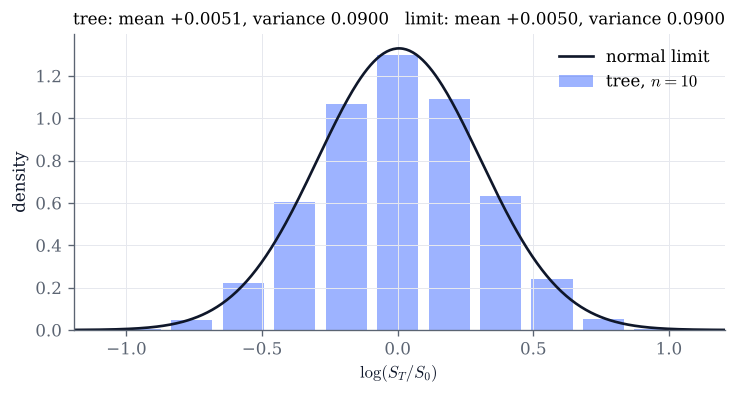

In [2]:
def tree_law(n=10, sigma=0.3, r=0.05, T=1.0):
    n_min = int(np.floor(r * r * T / sigma**2)) + 1    # no arbitrage needs n > r^2 T / sigma^2
    note = f" (n raised from {n}: the tree needs n > r²T/σ²)" if n < n_min else ""
    n = max(n, n_min)
    support, w = log_return_law(T, n, r, sigma)
    spacing = 2 * sigma * np.sqrt(T / n)
    m, s = (r - sigma**2 / 2) * T, sigma * np.sqrt(T)
    grid = np.linspace(m - 4 * s, m + 4 * s, 400)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.bar(support, w / spacing, width=0.8 * spacing, color=COBALT, alpha=0.45, label=f"tree, $n={n}$")
    ax.plot(grid, np.exp(-(grid - m)**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi)), color=INK,
            label="normal limit")
    mean, var = (w * support).sum(), (w * support**2).sum() - (w * support).sum()**2
    ax.set(xlim=(m - 4 * s, m + 4 * s), xlabel="$\\log(S_T/S_0)$", ylabel="density",
           title=f"tree: mean {mean:+.4f}, variance {var:.4f}   limit: mean {m:+.4f}, variance {s*s:.4f}")
    ax.legend(title=note.strip() or None, title_fontsize=7)
    plt.show()

tree_law()

In [3]:
# Explore: n is the number of periods; the limit does not depend on n.
interact(tree_law,
         n=IntSlider(value=10, min=1, max=400, continuous_update=False, description="n"),
         sigma=FloatSlider(value=0.3, min=0.05, max=1.0, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.05, max=0.15, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"));

## 2. Binomial prices converge to the Black–Scholes price

The call price in the $n$-period tree against $n$, with even and odd $n$ in different colours, and the Black–Scholes
price $S_0N(d_+) - Ke^{-rT}N(d_-)$ (Theorems 6.4 and 6.11). The right panel shows $n$ times the error: it stays
bounded, but whether it settles depends on where the strike falls in the lattice of terminal prices
(Remark 6.7). Try $K = S_0$, then a strike a little away from it.

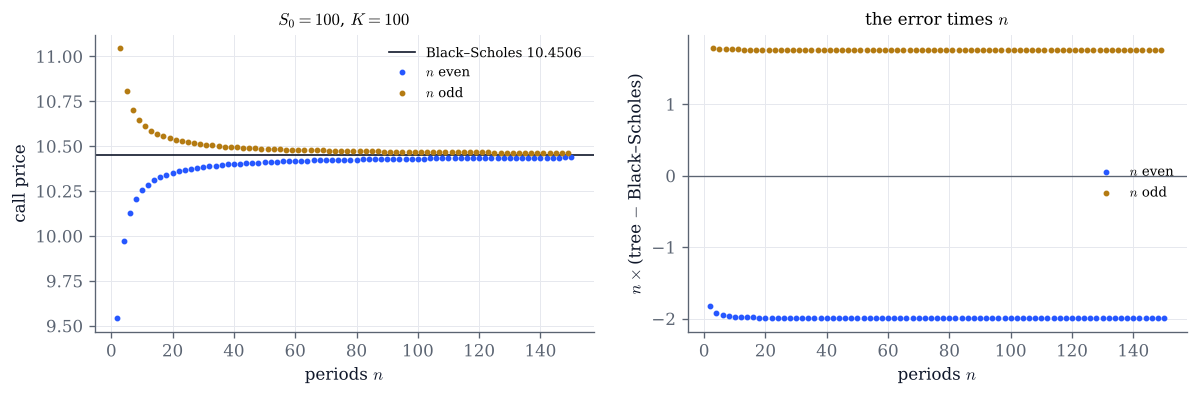

In [4]:
def convergence(K=100.0, sigma=0.2, r=0.05, T=1.0, n_max=150):
    S0 = 100.0
    exact = call(S0, K, T, r, sigma)
    n0 = int(np.floor(r * r * T / sigma**2)) + 1          # the tree needs n > r^2 T / sigma^2
    n = np.arange(max(n0, 2), n_max + 1)
    prices = np.array([binomial_call(S0, K, T, r, sigma, k) for k in n])
    even = n % 2 == 0
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.axhline(exact, color=INK, lw=1, label=f"Black–Scholes {exact:.4f}")
    ax.plot(n[even], prices[even], "o", ms=2.5, color=COBALT, label="$n$ even")
    ax.plot(n[~even], prices[~even], "o", ms=2.5, color=GOLD, label="$n$ odd")
    ax.set(xlabel="periods $n$", ylabel="call price", title=f"$S_0=100$, $K={K:g}$")
    ax.legend(fontsize=8)
    ax2.plot(n[even], n[even] * (prices[even] - exact), "o", ms=2.5, color=COBALT, label="$n$ even")
    ax2.plot(n[~even], n[~even] * (prices[~even] - exact), "o", ms=2.5, color=GOLD, label="$n$ odd")
    ax2.axhline(0, color=GREY, lw=0.8)
    ax2.set(xlabel="periods $n$", ylabel="$n\\times$(tree $-$ Black–Scholes)", title="the error times $n$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

convergence()

In [5]:
interact(convergence,
         K=FloatSlider(value=100.0, min=60.0, max=150.0, step=1.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.05, max=0.15, step=0.01, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         n_max=IntSlider(value=150, min=20, max=600, step=10, continuous_update=False, description="max n"));

## 3. The Greeks over spot and maturity

Each panel is a map of one Greek of the call (Proposition 6.14) over the spot $x$ (horizontal) and the time to maturity
$\tau$ (vertical, logarithmic). Close to maturity the delta becomes a step and the gamma and the theta concentrate at the
strike; the vega is largest for long maturities near the money. The relation
$\partial_t c + rx\,\partial_x c + \tfrac12\sigma^2x^2\,\partial_{xx} c = rc$ (equation (6.7)) is checked on the whole grid.

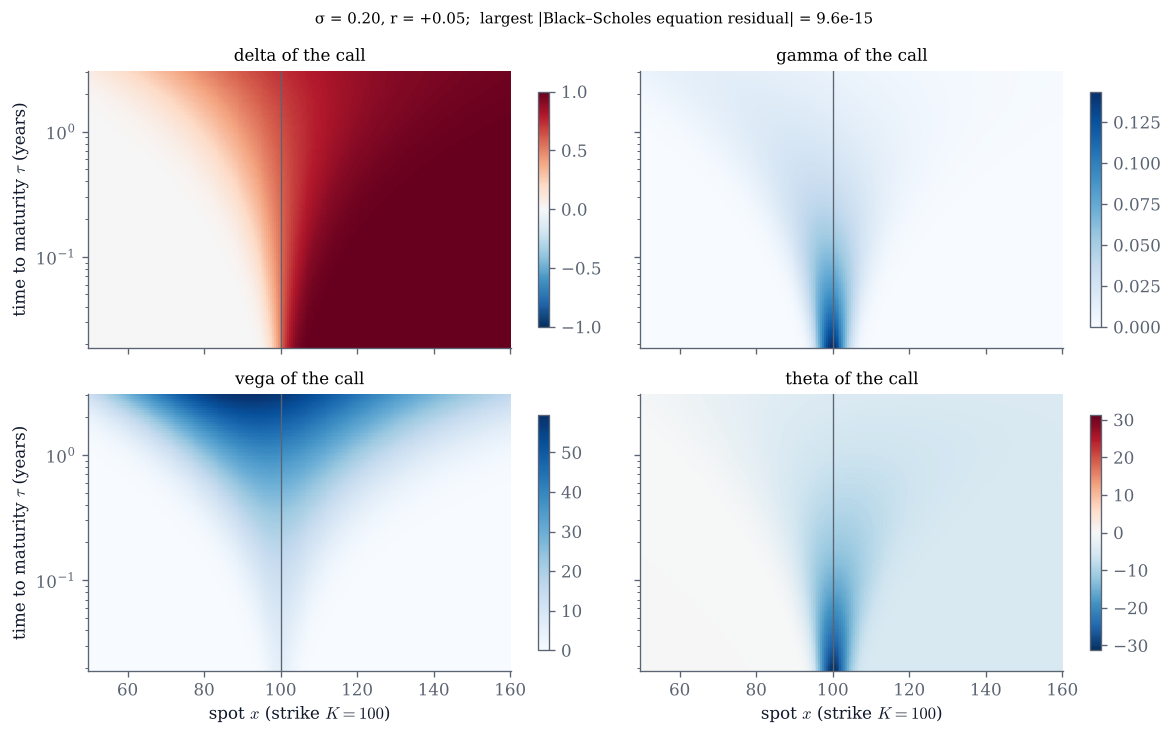

In [6]:
def greek_maps(kind="call", sigma=0.2, r=0.05):
    K = 100.0
    x = np.linspace(50, 160, 221)
    tau = np.logspace(np.log10(1 / 52), np.log10(3.0), 120)
    X, TAU = np.meshgrid(x, tau)
    g = greeks(X, K, TAU, r, sigma, kind)
    price = call(X, K, TAU, r, sigma) if kind == "call" else put(X, K, TAU, r, sigma)
    residual = g["theta"] + r * X * g["delta"] + 0.5 * sigma**2 * X**2 * g["gamma"] - r * price
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharex=True, sharey=True)
    for ax, key in zip(axes.flat, ("delta", "gamma", "vega", "theta")):
        z = g[key]
        if key in ("delta", "theta"):
            lim = np.abs(z).max(); cmap, vmin = "RdBu_r", -lim
        else:
            lim = z.max(); cmap, vmin = "Blues", 0
        im = ax.pcolormesh(X, TAU, z, cmap=cmap, vmin=vmin, vmax=lim, shading="auto")
        ax.axvline(K, color=GREY, lw=0.8)
        ax.set(yscale="log", title=f"{key} of the {kind}")
        ax.grid(False)
        fig.colorbar(im, ax=ax, shrink=0.85)
    for ax in axes[1]:
        ax.set_xlabel("spot $x$ (strike $K=100$)")
    for ax in axes[:, 0]:
        ax.set_ylabel("time to maturity $\\tau$ (years)")
    fig.suptitle(f"σ = {sigma:.2f}, r = {r:+.2f};  largest |Black–Scholes equation residual| = {np.abs(residual).max():.1e}",
                 fontsize=9)
    fig.tight_layout()
    plt.show()

greek_maps()

In [7]:
interact(greek_maps,
         kind=Dropdown(options=["call", "put"], value="call", description="option"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.05, max=0.15, step=0.01, continuous_update=False, description="r"));

## 4. Prices at intermediate times

Along each simulated path of the stock under $\mathbb Q$, the price of the call at time $t$ is $c(t,S_t)$
(Theorem 6.11, which conditions on $\mathcal F_t$ with the independence lemma). At maturity it meets the payoff.
On the right, the average of the discounted price $e^{-rt}c(t,S_t)$ over many paths stays at $c(0,S_0)$: the discounted
price is a martingale (Proposition 6.9), although each path wanders.

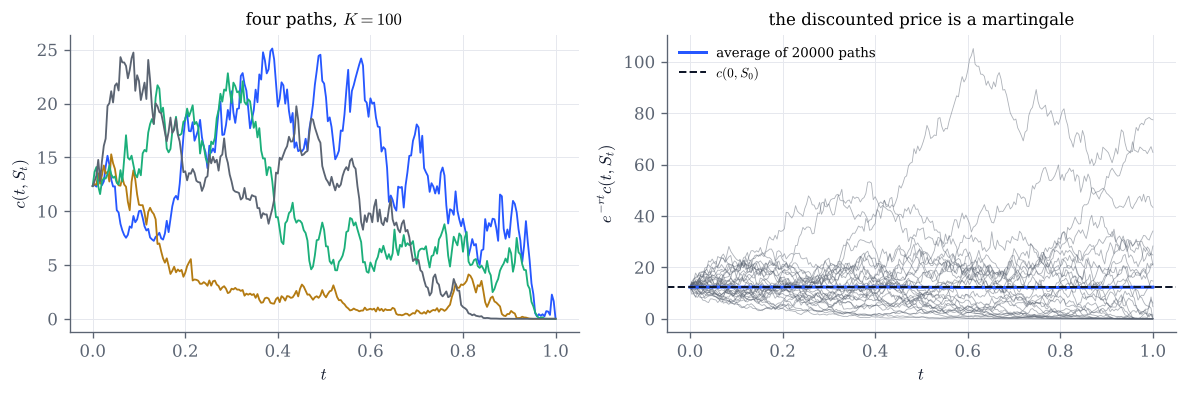

In [8]:
def along_paths(K=100.0, sigma=0.25, r=0.05, n_paths=20_000, seed=0):
    S0, T = 100.0, 1.0
    t, S = gbm_paths(S0, T, r, sigma, n_steps=250, n_paths=n_paths, seed=seed)
    V = call(S, K, T - t, r, sigma)                    # c(t, S_t); at t = T this is the payoff
    disc = np.exp(-r * t) * V
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for k, color in zip(range(4), (COBALT, GOLD, GREEN, GREY)):
        ax.plot(t, V[k], color=color, lw=1.1)
    ax.set(xlabel="$t$", ylabel="$c(t,S_t)$", title=f"four paths, $K={K:g}$")
    ax2.plot(t, disc[:30].T, color=GREY, lw=0.5, alpha=0.5)
    ax2.plot(t, disc.mean(0), color=COBALT, lw=1.8, label=f"average of {n_paths} paths")
    ax2.axhline(call(S0, K, T, r, sigma), color=INK, ls="--", lw=1.2, label="$c(0,S_0)$")
    ax2.set(xlabel="$t$", ylabel="$e^{-rt}c(t,S_t)$", title="the discounted price is a martingale")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

along_paths()

In [9]:
interact(along_paths,
         K=FloatSlider(value=100.0, min=60.0, max=150.0, step=1.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.25, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.05, min=-0.05, max=0.15, step=0.01, continuous_update=False, description="r"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 5. Rules of thumb at the money

At the at-the-money-forward strike $K = S_0e^{rT}$ the call and the put both cost $S_0\big(2N(v/2)-1\big)$, with
$v = \sigma\sqrt T$. Proposition 6.16 compares price, delta and vega with $0.4\,S_0\sigma\sqrt T$,
$0.5 + 0.2\,\sigma\sqrt T$ and $0.4\,S_0\sqrt T$. The plots show the relative errors against $\sigma$ for a maturity
of your choice; the error is of order $v^2$, plus a constant $0.27\%$ from rounding $1/\sqrt{2\pi}$ to $0.4$.

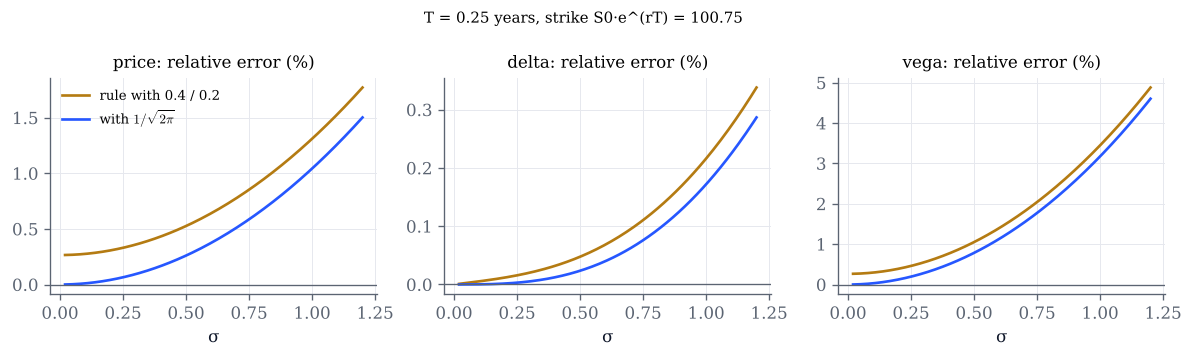

In [10]:
def rules_of_thumb(T=0.25, r=0.03):
    S0 = 100.0
    sig = np.linspace(0.02, 1.2, 200)
    K = S0 * np.exp(r * T)
    exact = atm_forward_call(S0, T, sig)
    g = greeks(S0, K, T, r, sig)
    v = sig * np.sqrt(T)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.0))
    pairs = (("price", exact, 0.4 * S0 * v, brenner_subrahmanyam(S0, T, sig)["price"]),
             ("delta", g["delta"], 0.5 + 0.2 * v, brenner_subrahmanyam(S0, T, sig)["delta"]),
             ("vega", g["vega"], 0.4 * S0 * np.sqrt(T) * np.ones_like(sig), brenner_subrahmanyam(S0, T, sig)["vega"]))
    for ax, (name, ex, rule, approx) in zip(axes, pairs):
        ax.plot(sig, 100 * (rule - ex) / ex, color=GOLD, label="rule with 0.4 / 0.2")
        ax.plot(sig, 100 * (approx - ex) / ex, color=COBALT, label="with $1/\\sqrt{2\\pi}$")
        ax.axhline(0, color=GREY, lw=0.8)
        ax.set(xlabel="σ", title=f"{name}: relative error (%)")
    axes[0].legend(fontsize=8)
    fig.suptitle(f"T = {T:g} years, strike S0·e^(rT) = {K:.2f}", fontsize=9)
    fig.tight_layout()
    plt.show()

rules_of_thumb()

In [11]:
interact(rules_of_thumb,
         T=FloatSlider(value=0.25, min=1/52, max=5.0, step=1/52, continuous_update=False, description="T"),
         r=FloatSlider(value=0.03, min=-0.05, max=0.15, step=0.01, continuous_update=False, description="r"));

## Things to try

- In section 1, take $r$ large, $\sigma$ small and $n=1$. The figure raises $n$: why can the tree not have fewer periods?
  For $n$ small, compare the mean and the variance of the tree with those of the limit.
- In section 2, compare $K=100$, $K=101$ and $K=110$. For which strike do the even and odd errors line up on two
  smooth curves, and why?
- In section 3, switch between the call and the put. Which maps coincide, and which differ by a constant? Use put–call
  parity to explain.
- In section 4, move $K$ far out of the money. The average still stays flat, but individual paths look very different. Why?
- In section 5, look at the blue curves (the versions with $1/\sqrt{2\pi}$): the relative error of the vega is about
  three times that of the price. Find the reason in the bounds of Proposition 6.16. Why do the gold curves (the rounded
  rules) not start at zero?